# Updated best ones — top 20 across completed sweeps

**Saved results only: no experiments rerun.** Includes all nine families of
comparable, paired numerical checks: broad finite iterations; focused budgets/Delta;
rho initialization; fully solved matched L2; earlier LS-auxiliary penalized fits;
earlier intercept-aware penalized fits; earlier exact matched penalties; the new
finite-intercept sweep; and the new no-intercept five-solver sweep.

**“Best” means closest conditional posterior shape to the archived original**, ranked
by mean total-variation distance across two numerical checks (0=identical, 1=maximal
difference). No P(1) cutoff or probability bonus. Full age support is used, including
mass excluded by Delta. Only configurations with two saved numerical checks qualify:
this is not a claim that every primary-screening candidate has been revalidated.
Historical pre-audit runs with incompatible count priors/likelihood conventions
are not pooled. Original data and archived posterior are unchanged.

All LS/L1/L2/finite-fit and intercept choices are clearly identified. The overall
list does **not** silently impose the later matched-logistic/no-L1 preference;
a separate preferred-subset table follows. L2/L1 constants in fit labels are the
actual objective penalty coefficients, not sklearn's inverse-regularization C.
“Full solve” denotes convergence-seeking fitting, not a finite iteration budget.
For iterative fits, budgets count solver iterations (SGD/SAGA count epochs).
Rho updates are a separate outer procedure; -1 denotes a direct approximate estimate.

The 512-draw/seed42 and 1,024-draw/seed123 ranges are **numerical sensitivity, not
confidence intervals**. These are post-hoc, same-data selections, not calibrated
model comparisons or independent-data validation. Moment residuals are reported;
state equations remain heuristic for penalized and early-stopped fits. Shape
similarity to the original is a requested descriptive target, not proof of validity.


In [1]:
from tools.myocardial_updated_best_ones import *
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'axes.labelsize':11,'xtick.labelsize':10,'ytick.labelsize':10,'figure.dpi':160,
    'axes.spines.top':False,'axes.spines.right':False})
ranked,curves,reference=load_updated()
best=ranked.head(20).copy()
assert len(best)==20
digest=hashlib.sha256(Path('tools/myocardial_updated_best_ones.py').read_bytes()).hexdigest()[:12]
report_root=Path('results')/('myocardial_updated_best_ones_'+digest)
report_root.mkdir(exist_ok=True)
ranked.to_csv(report_root/'all_checked_candidates.csv',index=False)
best.to_csv(report_root/'top_twenty.csv',index=False)
print(f'{len(ranked)} distinct paired-check configurations across {ranked.stage.nunique()} study families.')
print('Ranked inventory by study:');display(ranked.groupby('stage').size().rename('Candidates').to_frame())
settings,metrics=clear_tables(best)
settings.to_csv(report_root/'top_twenty_settings.csv',index=False)
metrics.to_csv(report_root/'top_twenty_metrics.csv',index=False)
print('Settings — ranks link directly to the metrics and individual figures below:')
show_table(settings)
print('Outcomes — smaller shape TV is better; numerical ranges are not confidence intervals:')
show_table(metrics)
print('Exact checkpoint paths and machine-readable tables:',report_root)


/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


188 distinct paired-check configurations across 9 study families.
Ranked inventory by study:


,Candidates
stage,
broad,13
earlier_LS_penalty,44
earlier_exact_match,9
earlier_intercept,58
finite_intercept,20
focused,15
fully_solved_matched_L2,6
initializations,8
no_intercept_solver_sweep,15


Settings — ranks link directly to the metrics and individual figures below:


Rank,Auxiliary fit,Posterior fit,Intercept,Delta,Rho updates,Rho initialization,Matched logistic fits
1,LS,Logistic FISTA 16 iterations,No,5,24,identity,No
2,LS,Logistic FISTA 12 iterations,No,2,20,identity,No
3,LS,Logistic FISTA 16 iterations,No,2,20,identity,No
4,LS,Logistic L1 0.0001 (full solve),No,1,30,identity,No
5,LS,Logistic L-BFGS 5 iterations,No,5,20,identity,No
6,LS,Logistic L-BFGS 5 iterations,No,10,20,identity,No
7,Logistic L1 0.0001 (full solve),Logistic L2 1.5e-06 (full solve),Yes,1,30,identity,No
8,Logistic L1 0.0001 (full solve),Logistic L2 1.2e-06 (full solve),Yes,1,30,identity,No
9,LS,Logistic L-BFGS 5 iterations,No,2,16,identity,No
10,Logistic L1 0.0001 (full solve),Logistic L2 1e-06 (full solve),Yes,1,10,identity,No


Outcomes — smaller shape TV is better; numerical ranges are not confidence intervals:


Rank,"P(1), numerical range",Shape TV ↓,Check-to-check TV ↓,Conditional peak age,Min. mass above age 55,Rho moment residual,Study
1,0.2609 – 0.2656,0.169500,0.031300,81,0.900200,0.013,focused
2,0.4300 – 0.4374,0.176000,0.024200,80,0.934600,0.0132,focused
3,0.4637 – 0.4827,0.216700,0.030600,81,0.958400,0.0132,focused
4,0.4016 – 0.4534,0.245100,0.053300,79,0.786800,0.013,earlier_LS_penalty
5,0.2057 – 0.2147,0.248700,0.062300,84,0.901000,0.0131,focused
6,0.2018 – 0.2056,0.266200,0.034300,83,0.947700,0.0131,focused
7,0.7177 – 0.7472,0.290700,0.036300,81,1.000000,0.114,earlier_intercept
8,0.6021 – 0.6308,0.298100,0.033900,81,1.000000,0.114,earlier_intercept
9,0.3057 – 0.3164,0.305300,0.065900,84,0.921700,0.0136,focused
10,0.8458 – 0.8504,0.344000,0.009600,81,1.000000,0.158,earlier_intercept


Exact checkpoint paths and machine-readable tables: results/myocardial_updated_best_ones_64c8367cda88


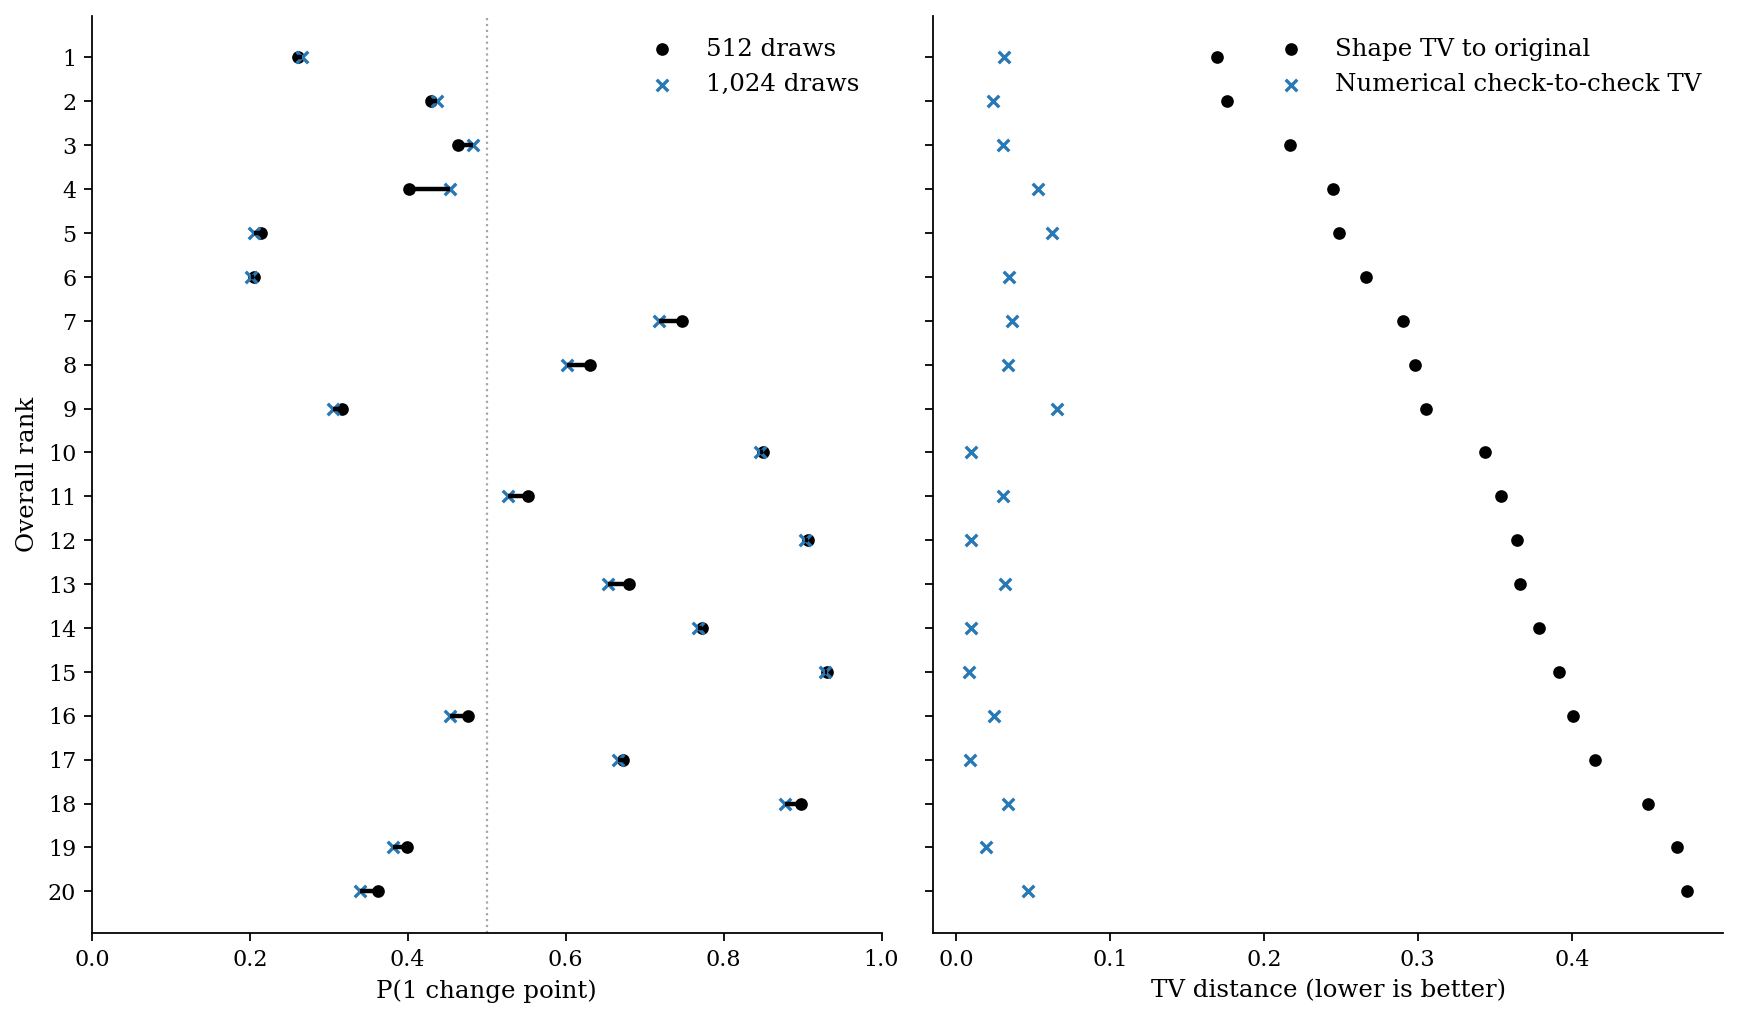

In [2]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(11,6.5),sharey=True)
y=np.arange(1,21)
ax.hlines(y,best.P1_min,best.P1_max,color='black',lw=2)
ax.scatter(best.primary_P1,y,color='black',s=22,label='512 draws')
ax.scatter(best.check_P1,y,color='#2878b5',marker='x',s=27,label='1,024 draws')
ax.axvline(.5,color='.65',lw=1,ls=':');ax.set_xlim(0,1)
ax.set(xlabel='P(1 change point)',ylabel='Overall rank',yticks=y)
ax.invert_yaxis();ax.legend(frameon=False)
bx.scatter(best.mean_TV,y,color='black',s=22,label='Shape TV to original')
bx.scatter(best.numerical_curve_TV,y,color='#2878b5',marker='x',s=27,label='Numerical check-to-check TV')
bx.set_xlabel('TV distance (lower is better)');bx.legend(frameon=False)
fig.tight_layout();plt.show()


### #1 — focused

**Auxiliary:** LS  
**Posterior:** Logistic FISTA 16 iterations  
**Intercept:** No; **Delta:** 5; **rho updates:** 24; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.013.

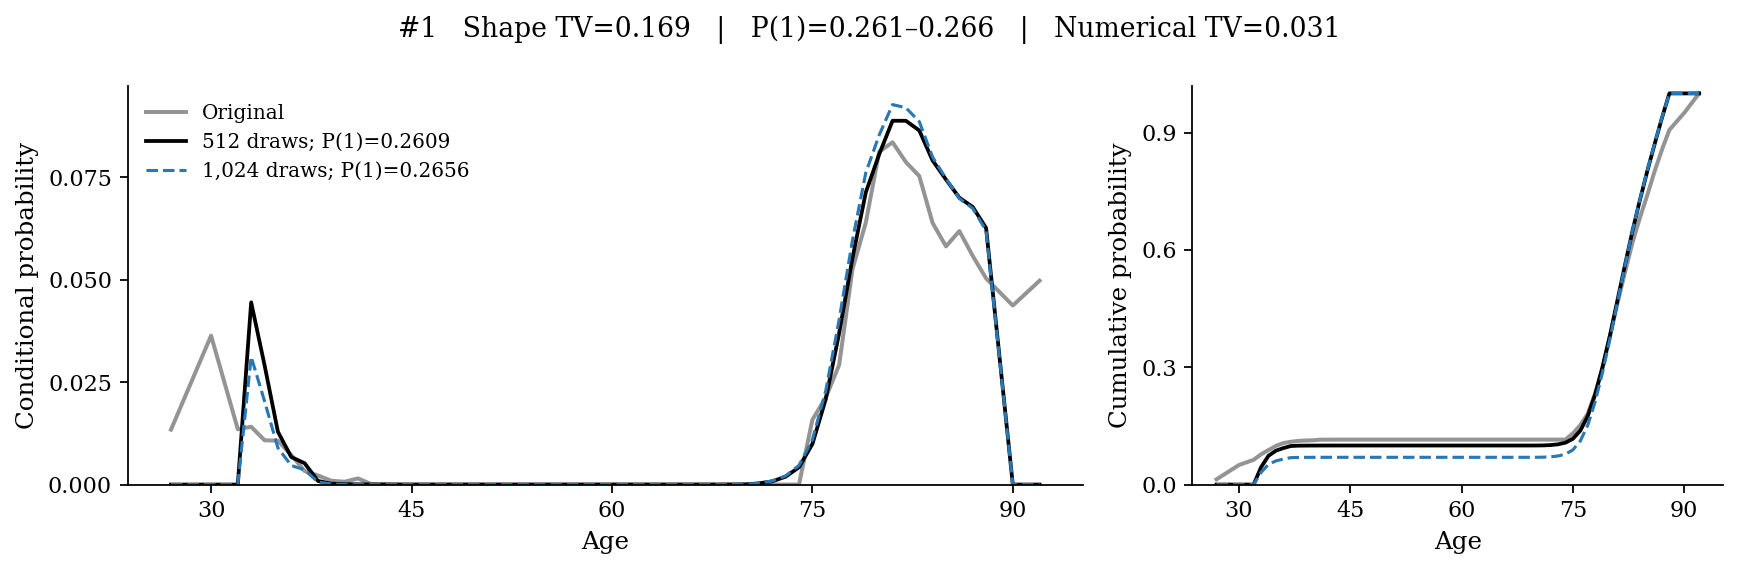

In [3]:
row=best.iloc[0]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #2 — focused

**Auxiliary:** LS  
**Posterior:** Logistic FISTA 12 iterations  
**Intercept:** No; **Delta:** 2; **rho updates:** 20; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.0132.

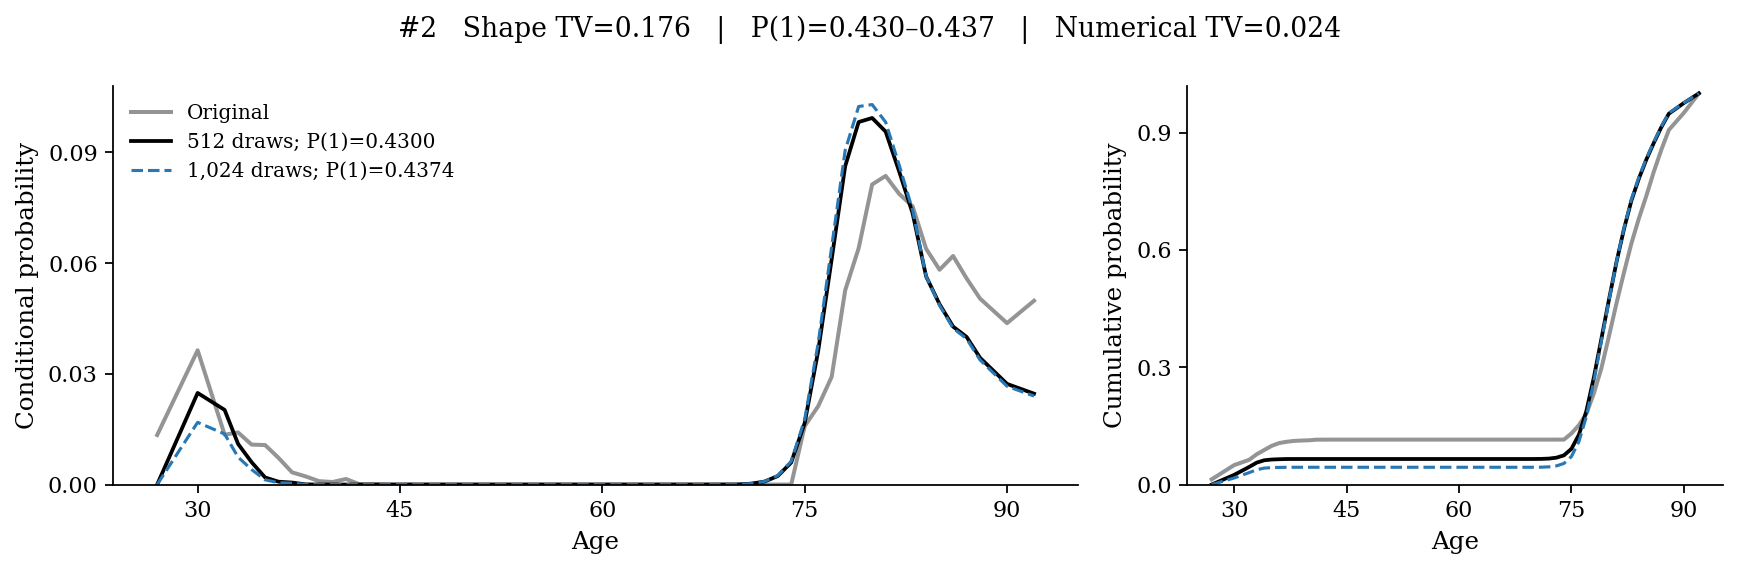

In [4]:
row=best.iloc[1]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #3 — focused

**Auxiliary:** LS  
**Posterior:** Logistic FISTA 16 iterations  
**Intercept:** No; **Delta:** 2; **rho updates:** 20; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.0132.

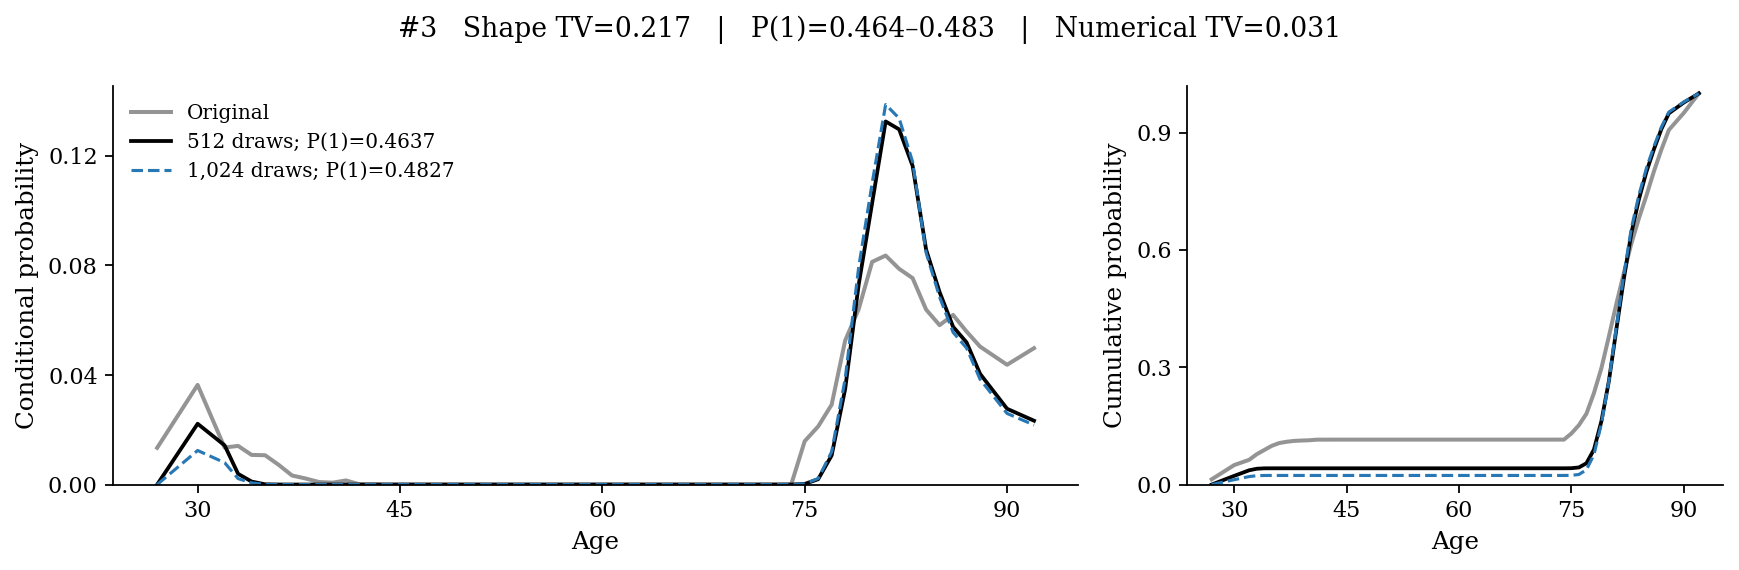

In [5]:
row=best.iloc[2]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #4 — earlier_LS_penalty

**Auxiliary:** LS  
**Posterior:** Logistic L1 0.0001 (full solve)  
**Intercept:** No; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.013.

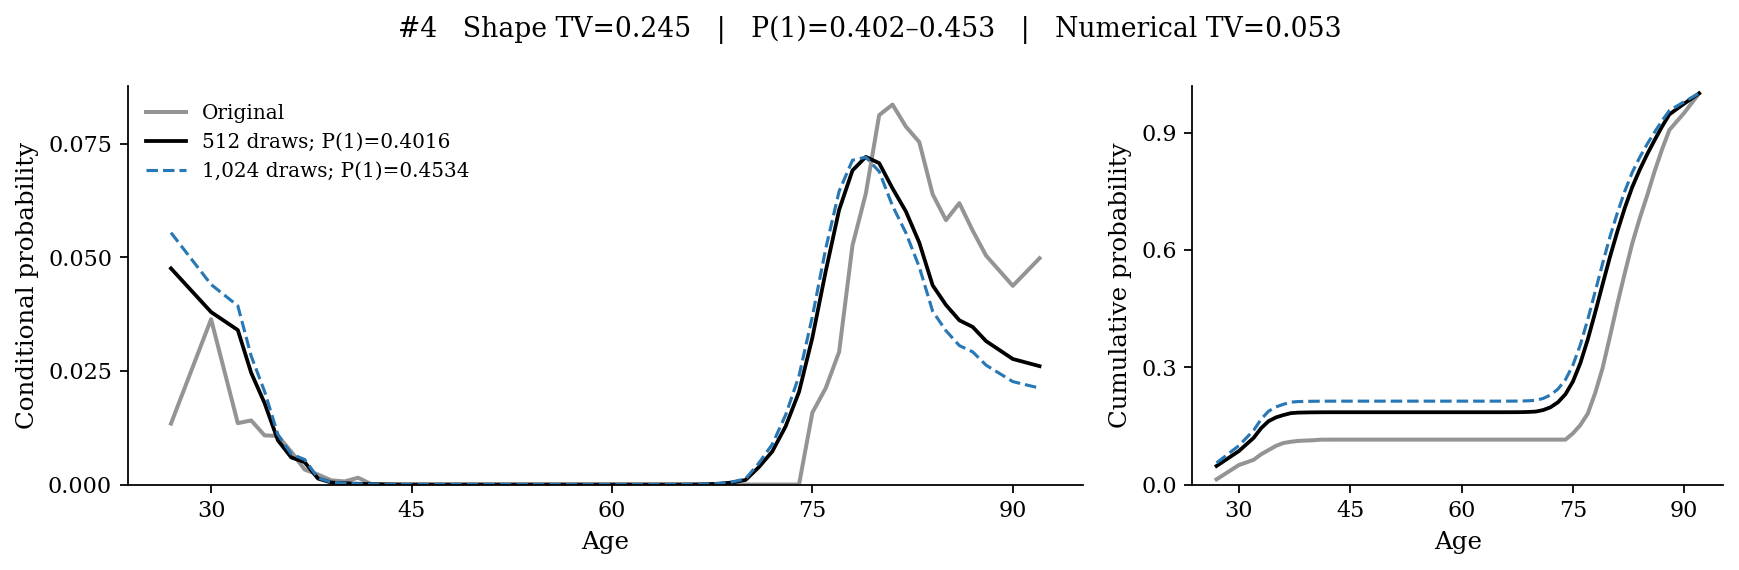

In [6]:
row=best.iloc[3]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #5 — focused

**Auxiliary:** LS  
**Posterior:** Logistic L-BFGS 5 iterations  
**Intercept:** No; **Delta:** 5; **rho updates:** 20; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.0131.

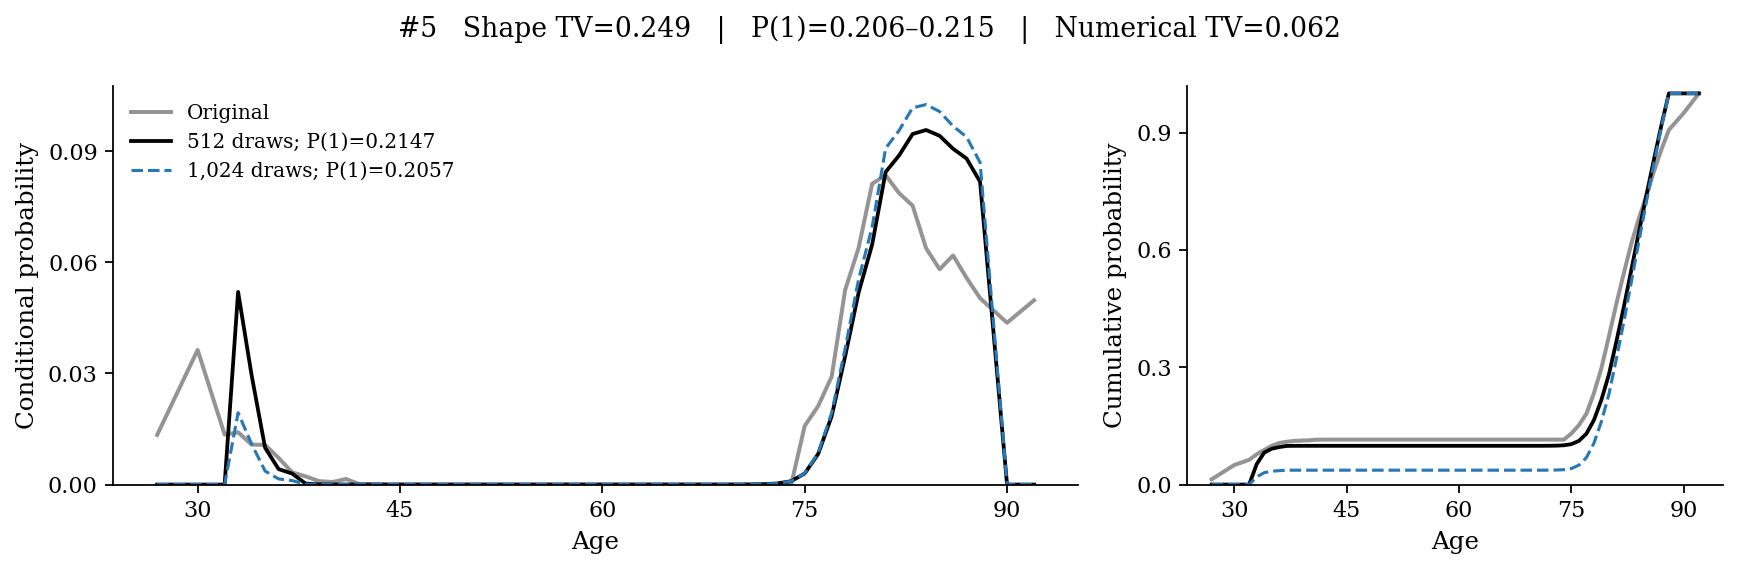

In [7]:
row=best.iloc[4]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #6 — focused

**Auxiliary:** LS  
**Posterior:** Logistic L-BFGS 5 iterations  
**Intercept:** No; **Delta:** 10; **rho updates:** 20; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.0131.

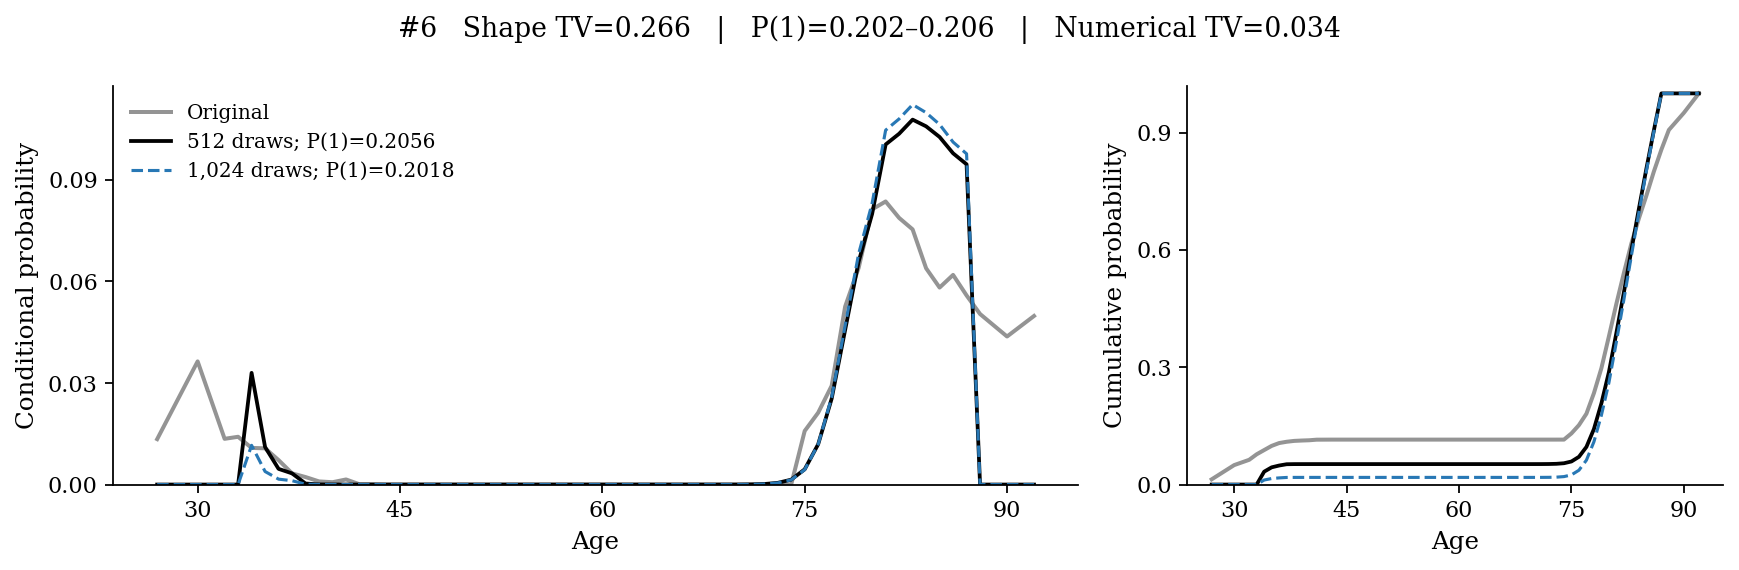

In [8]:
row=best.iloc[5]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #7 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 1.5e-06 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

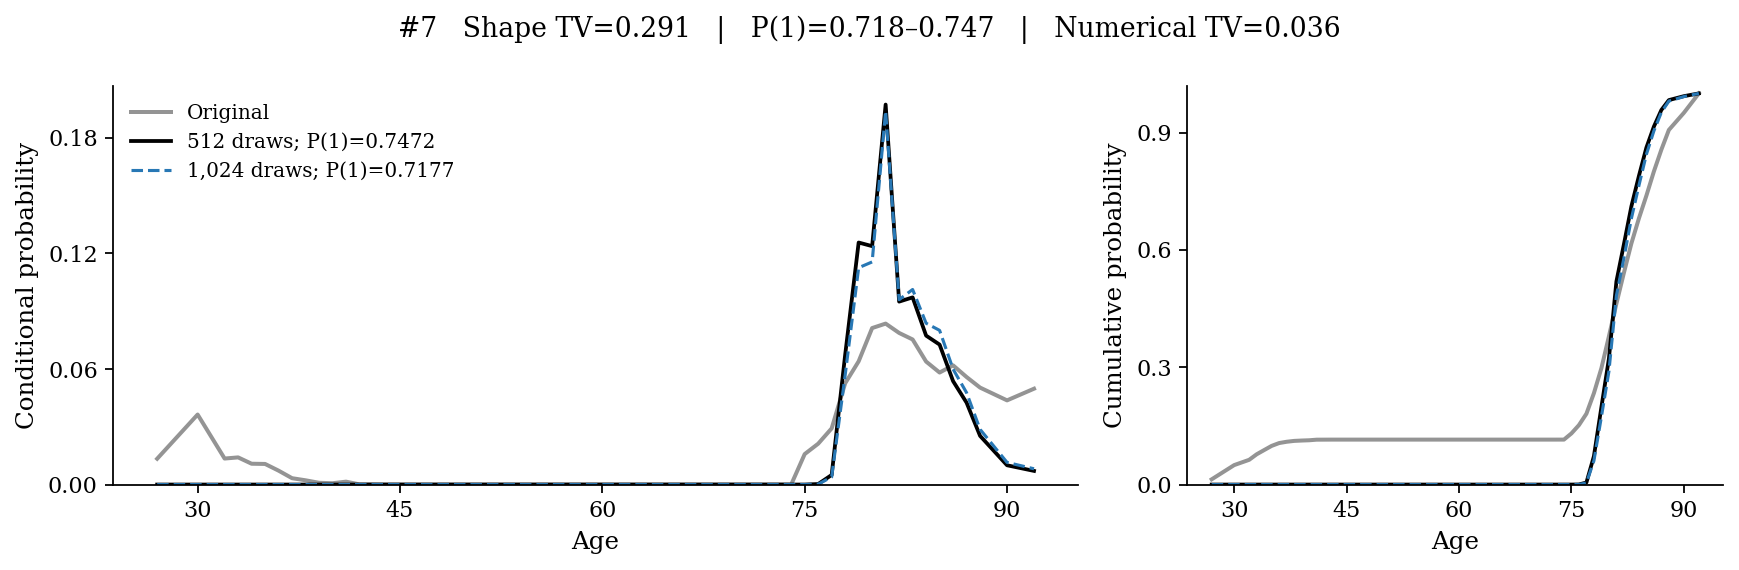

In [9]:
row=best.iloc[6]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #8 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 1.2e-06 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

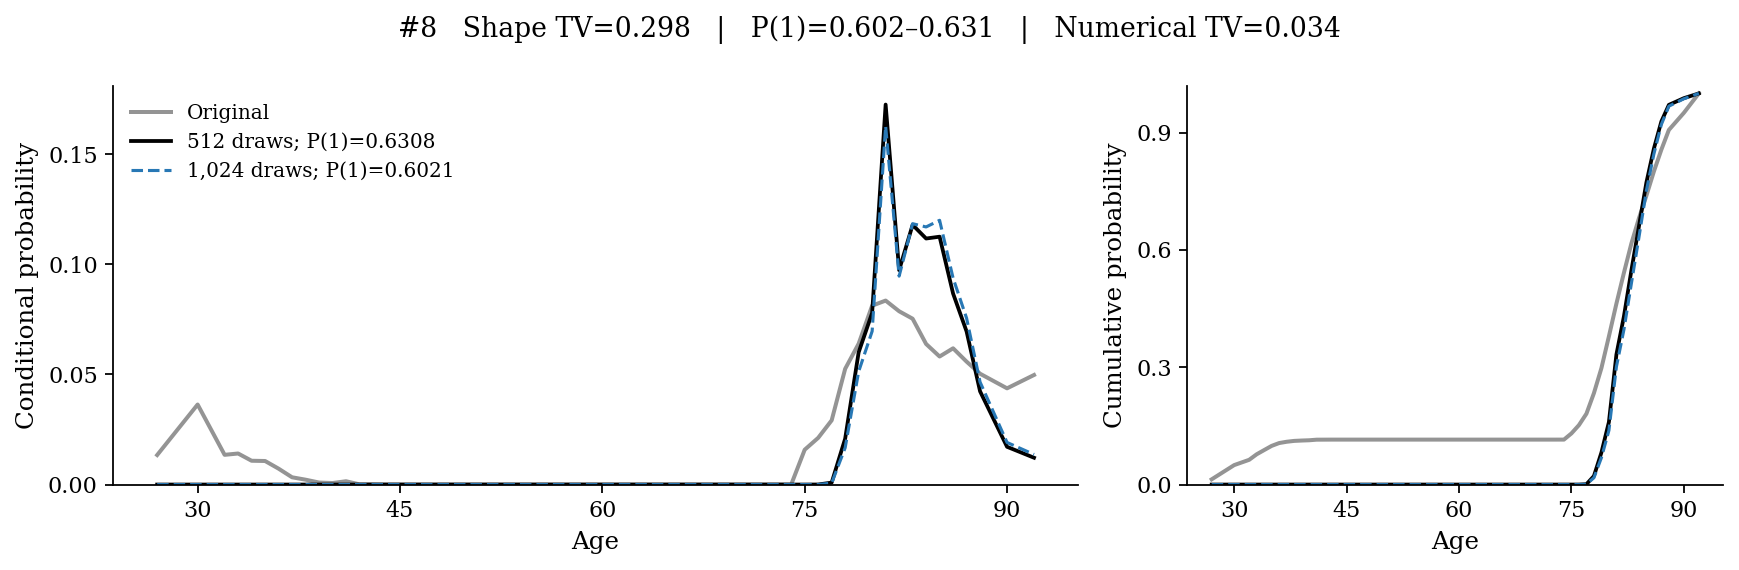

In [10]:
row=best.iloc[7]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #9 — focused

**Auxiliary:** LS  
**Posterior:** Logistic L-BFGS 5 iterations  
**Intercept:** No; **Delta:** 2; **rho updates:** 16; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.0136.

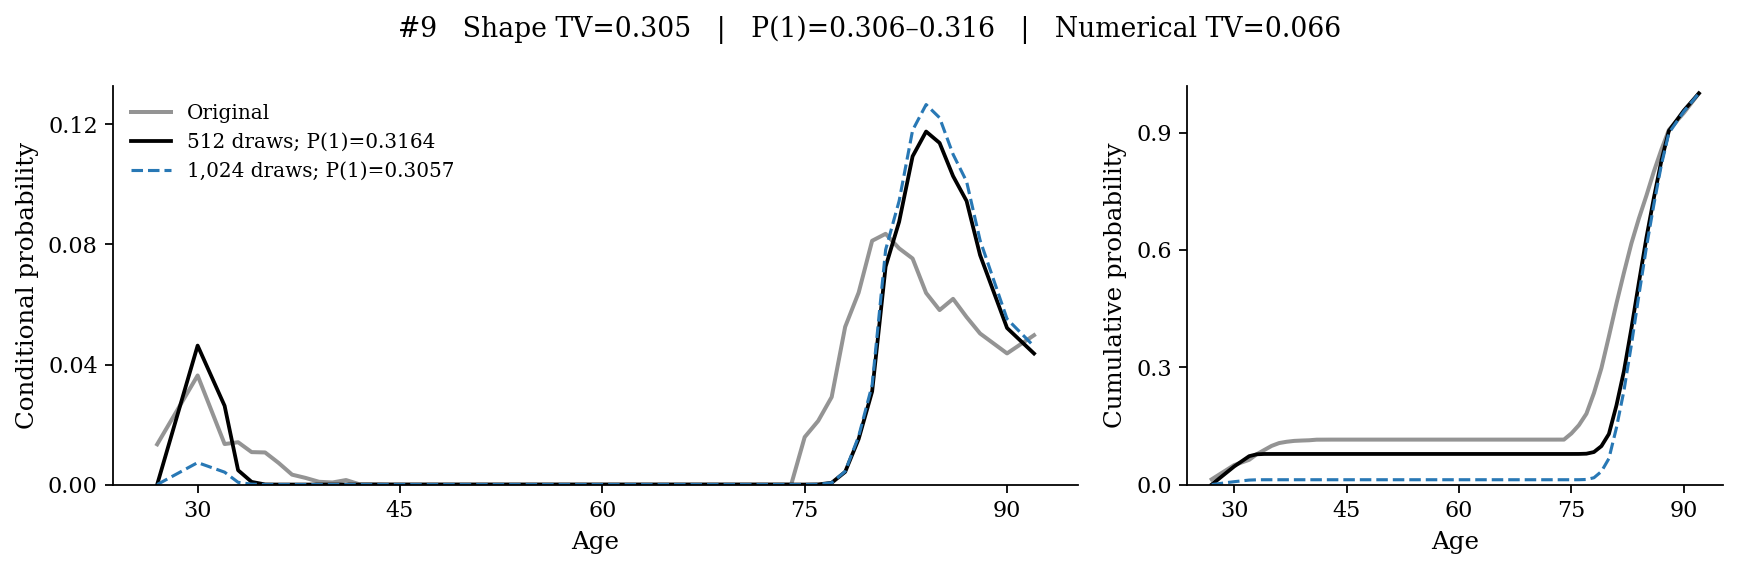

In [11]:
row=best.iloc[8]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #10 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 1e-06 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 10; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.158.

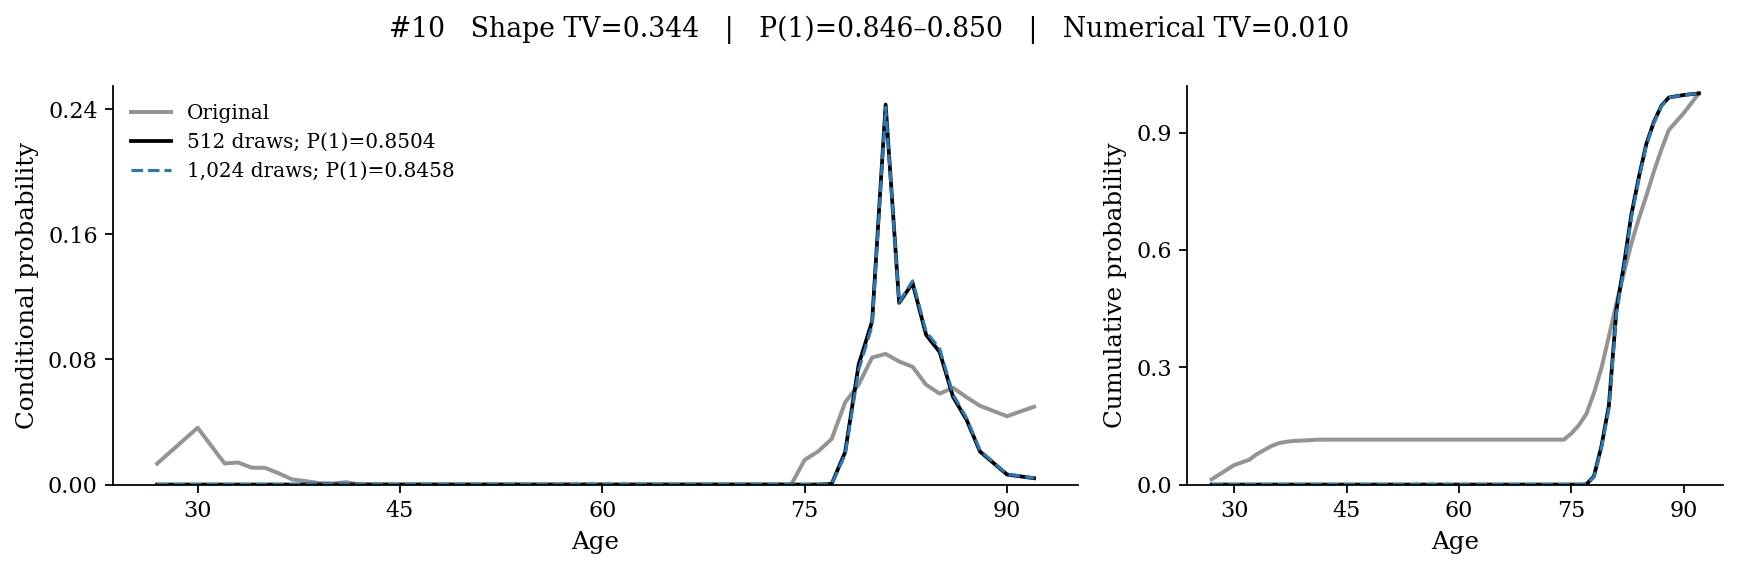

In [12]:
row=best.iloc[9]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #11 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 1e-06 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

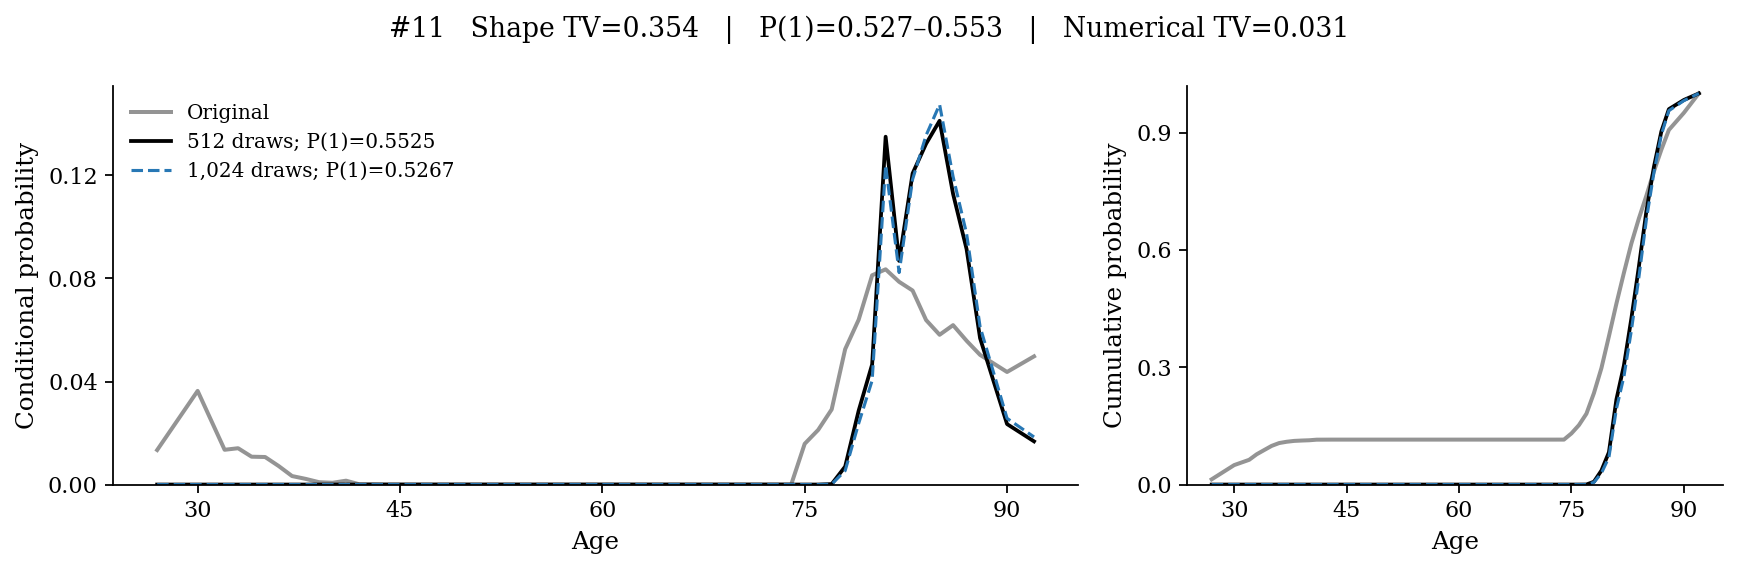

In [13]:
row=best.iloc[10]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #12 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 1.2e-06 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 10; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.158.

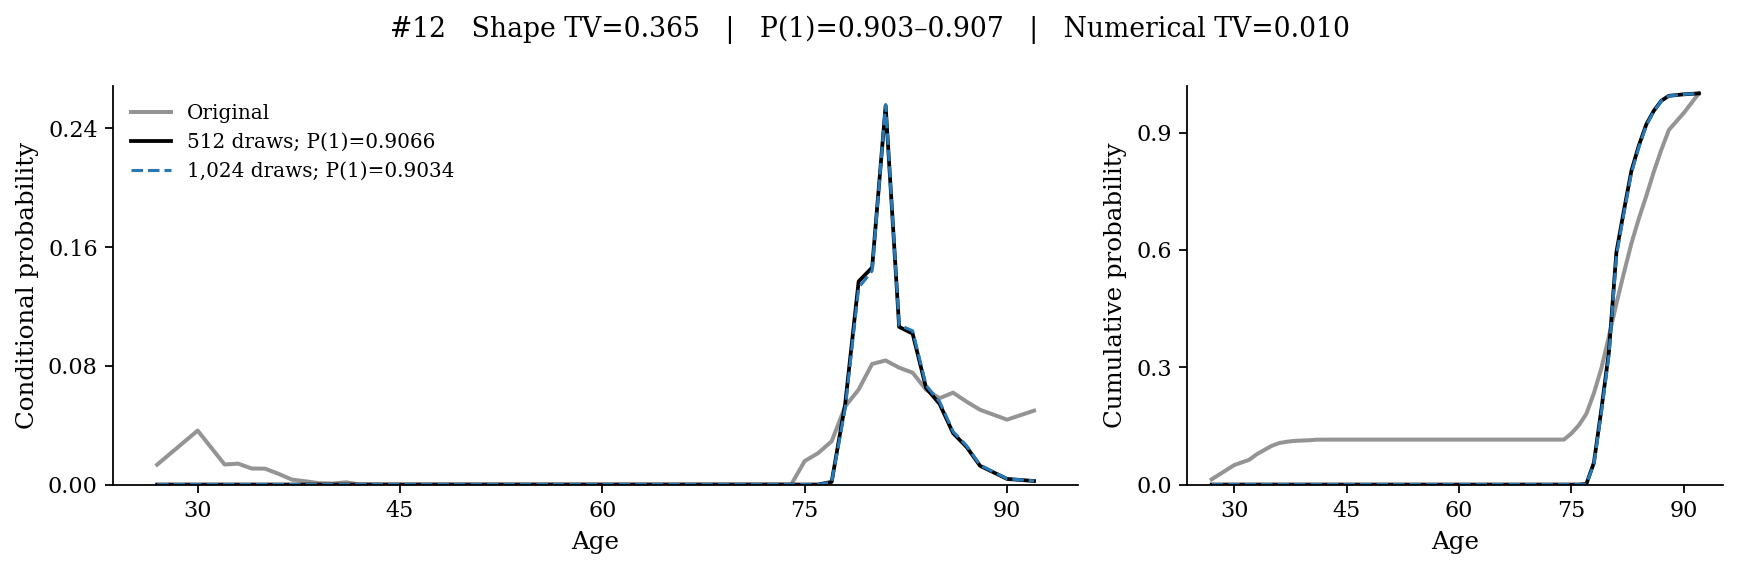

In [14]:
row=best.iloc[11]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #13 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L1 1e-05 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

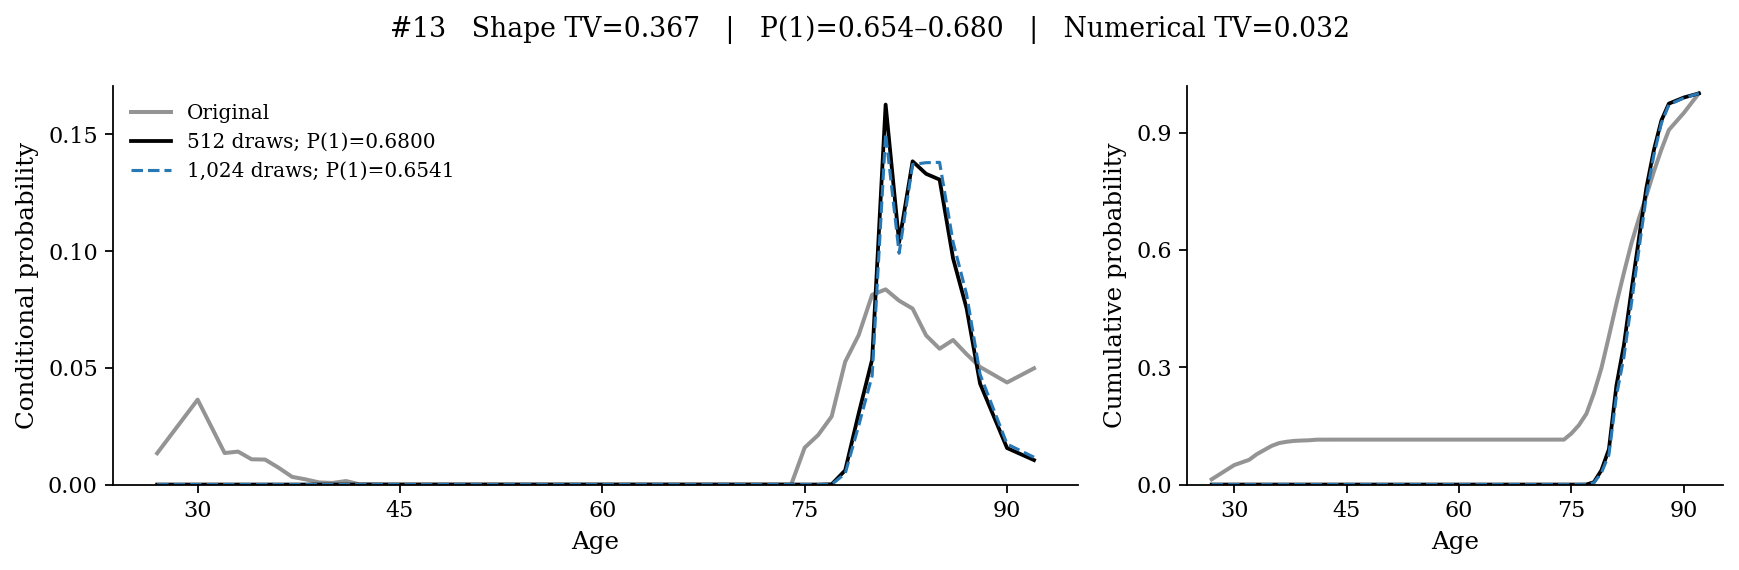

In [15]:
row=best.iloc[12]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #14 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 8e-07 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 10; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.158.

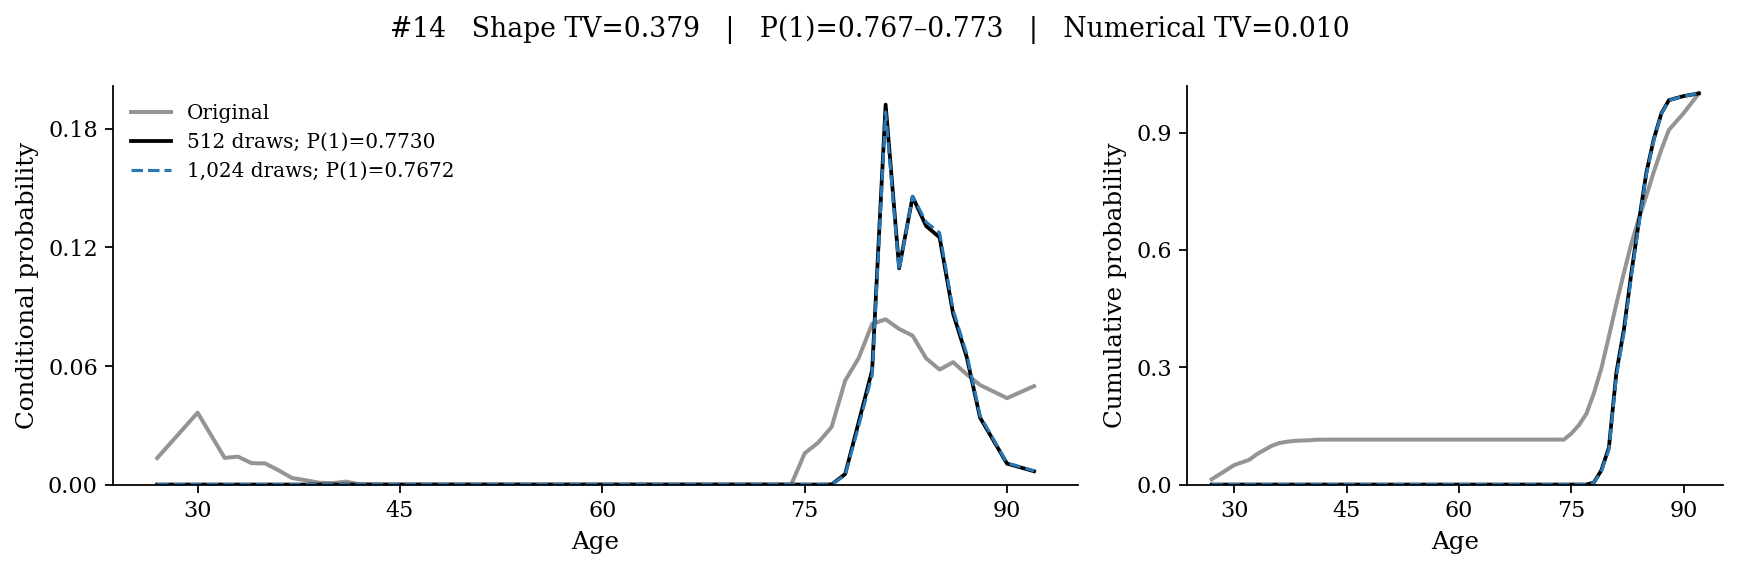

In [16]:
row=best.iloc[13]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #15 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L1 1e-05 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 10; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.158.

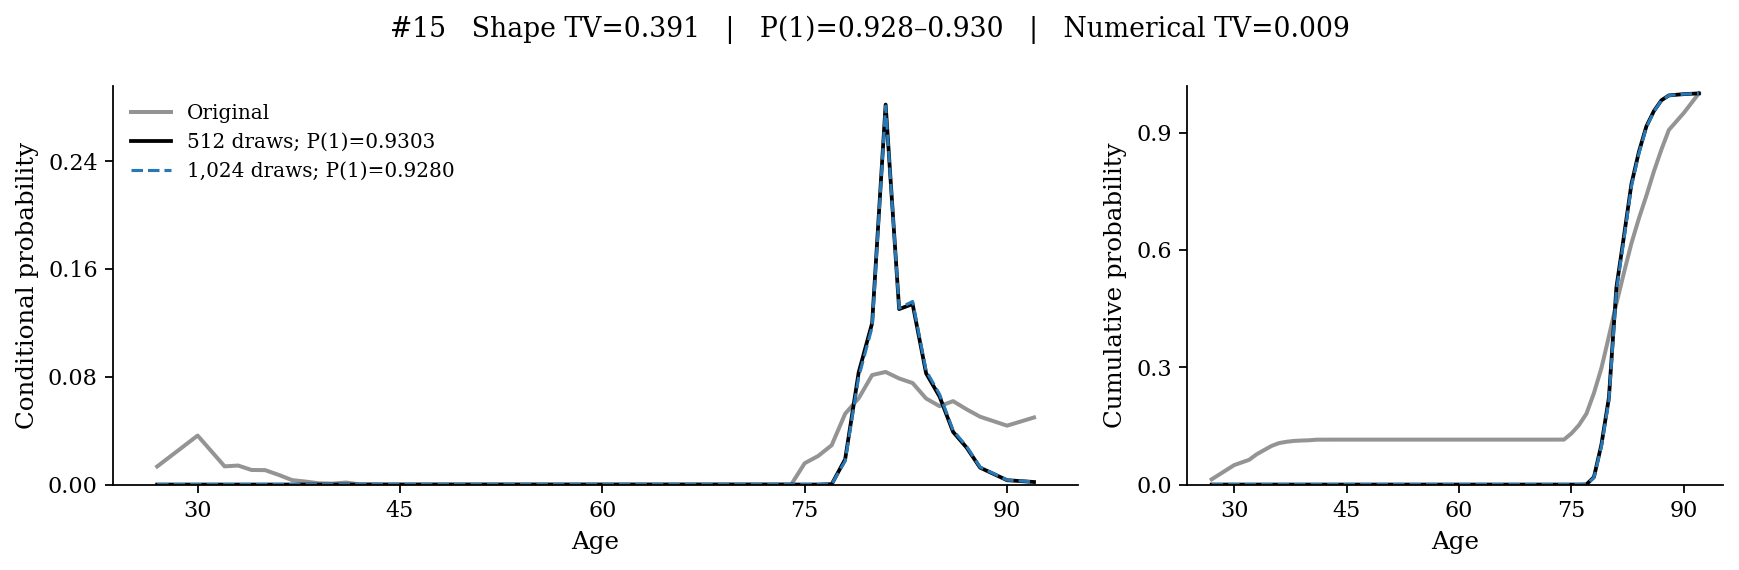

In [17]:
row=best.iloc[14]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #16 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 8e-07 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

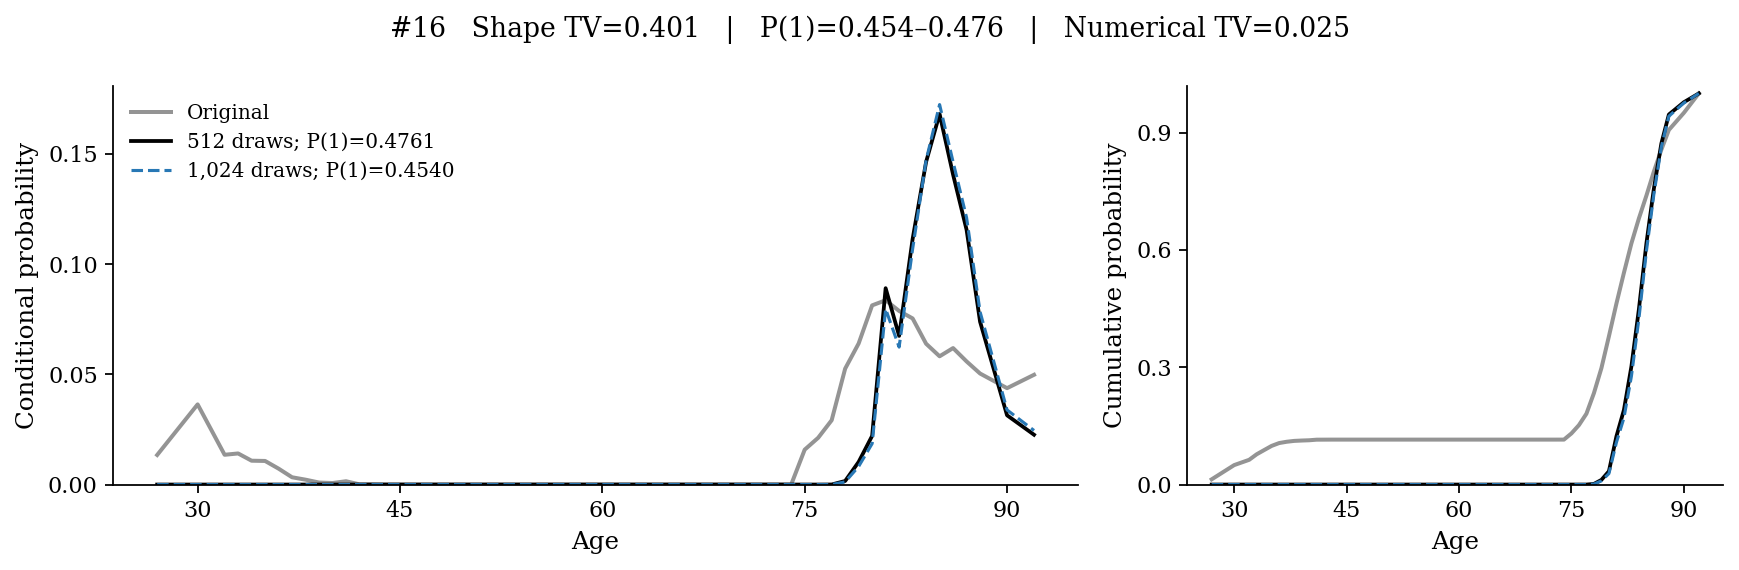

In [18]:
row=best.iloc[15]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #17 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 6e-07 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 10; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.158.

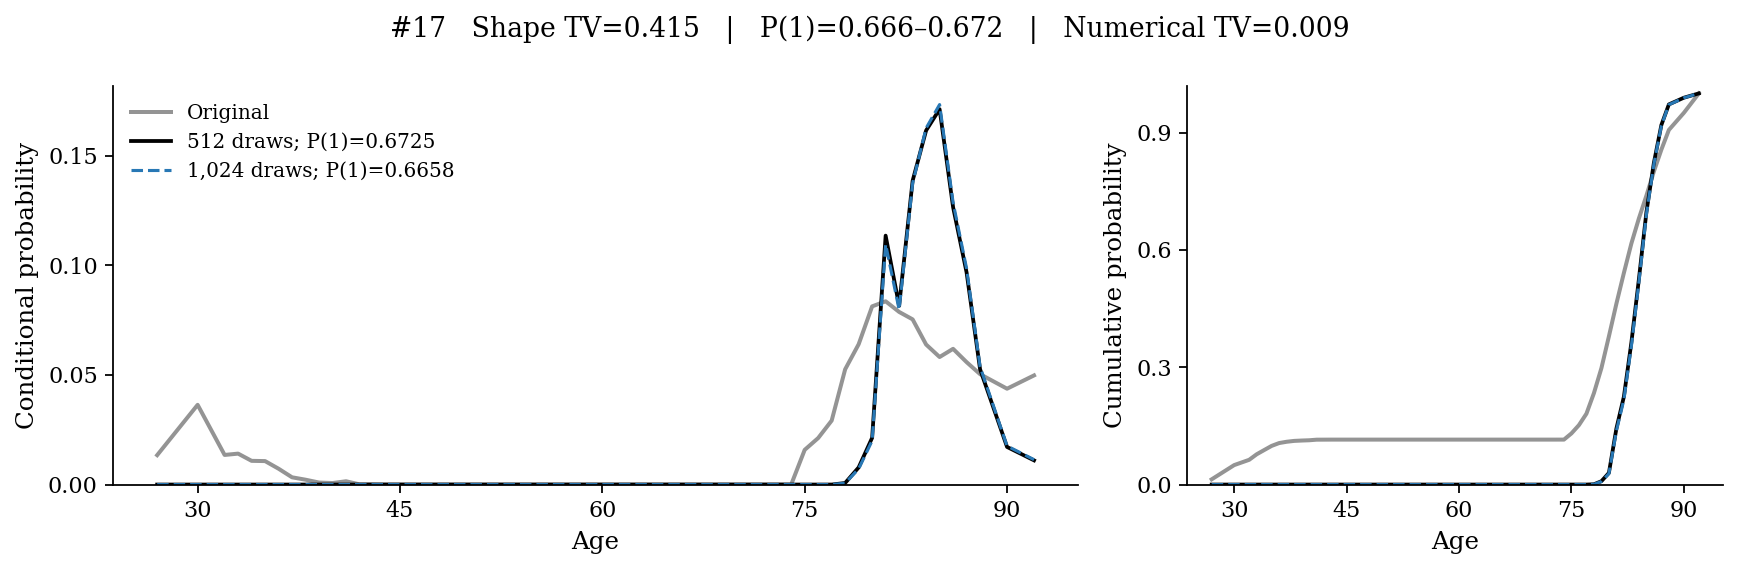

In [19]:
row=best.iloc[16]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #18 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 2e-06 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

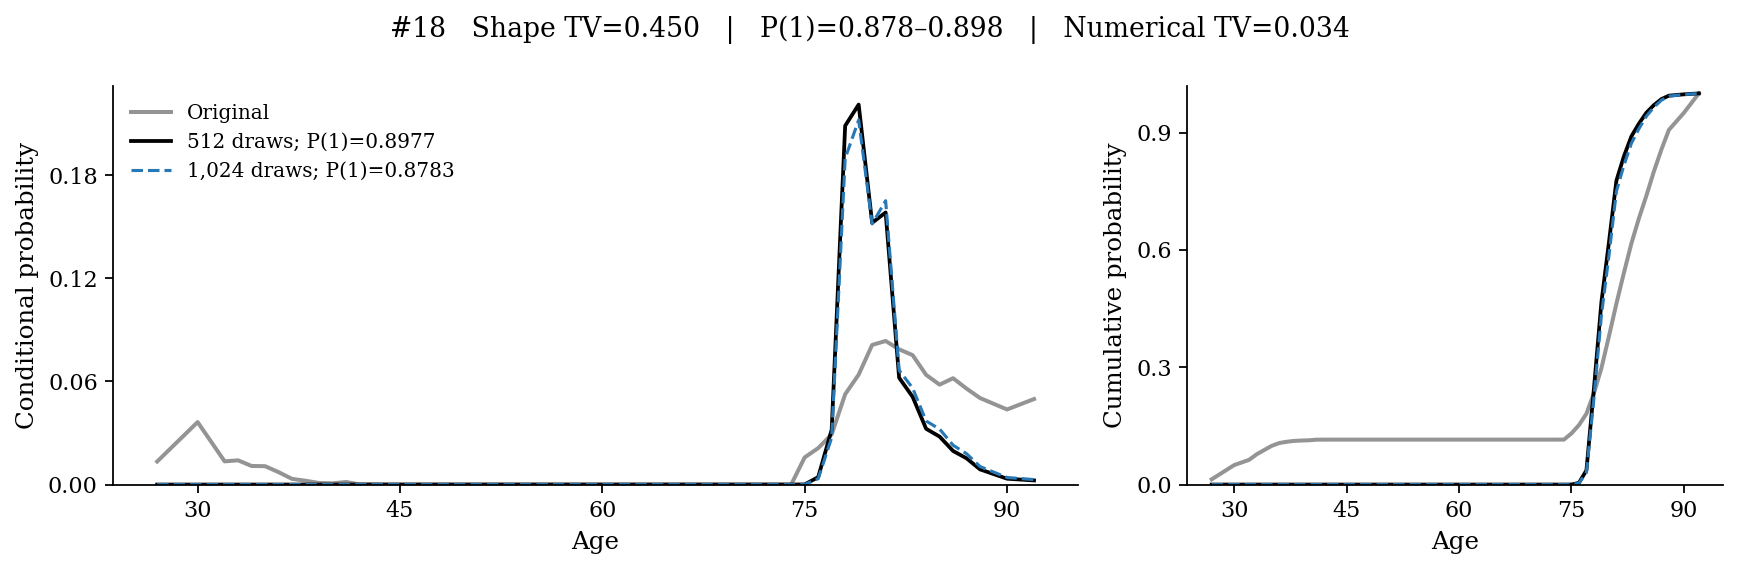

In [20]:
row=best.iloc[17]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #19 — earlier_intercept

**Auxiliary:** Logistic L1 0.0001 (full solve)  
**Posterior:** Logistic L2 6e-07 (full solve)  
**Intercept:** Yes; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
Uses intercept; mismatched penalties. Moment-equation residual: 0.114.

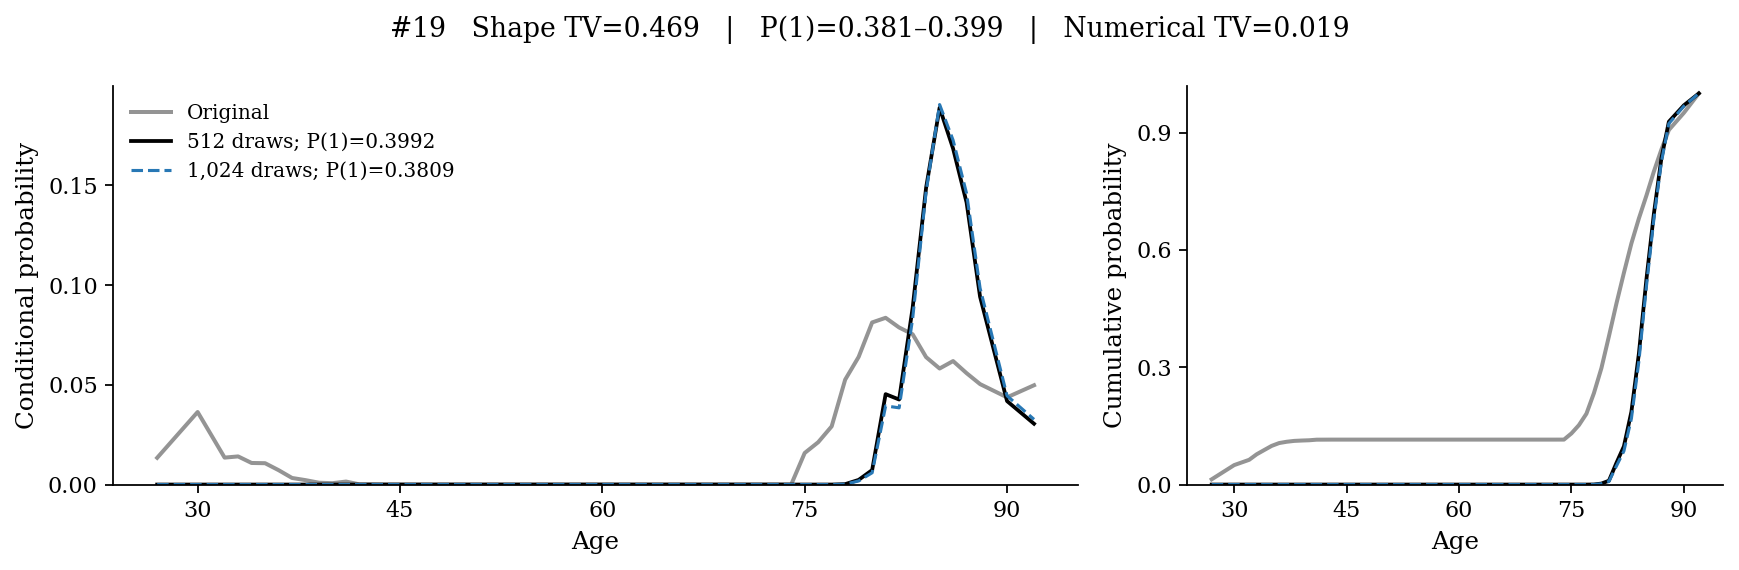

In [21]:
row=best.iloc[18]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


### #20 — earlier_LS_penalty

**Auxiliary:** LS  
**Posterior:** Logistic L2 3.16227766017e-06 (full solve)  
**Intercept:** No; **Delta:** 1; **rho updates:** 30; **rho initialization:** identity.  
No intercept; LS auxiliary. Moment-equation residual: 0.013.

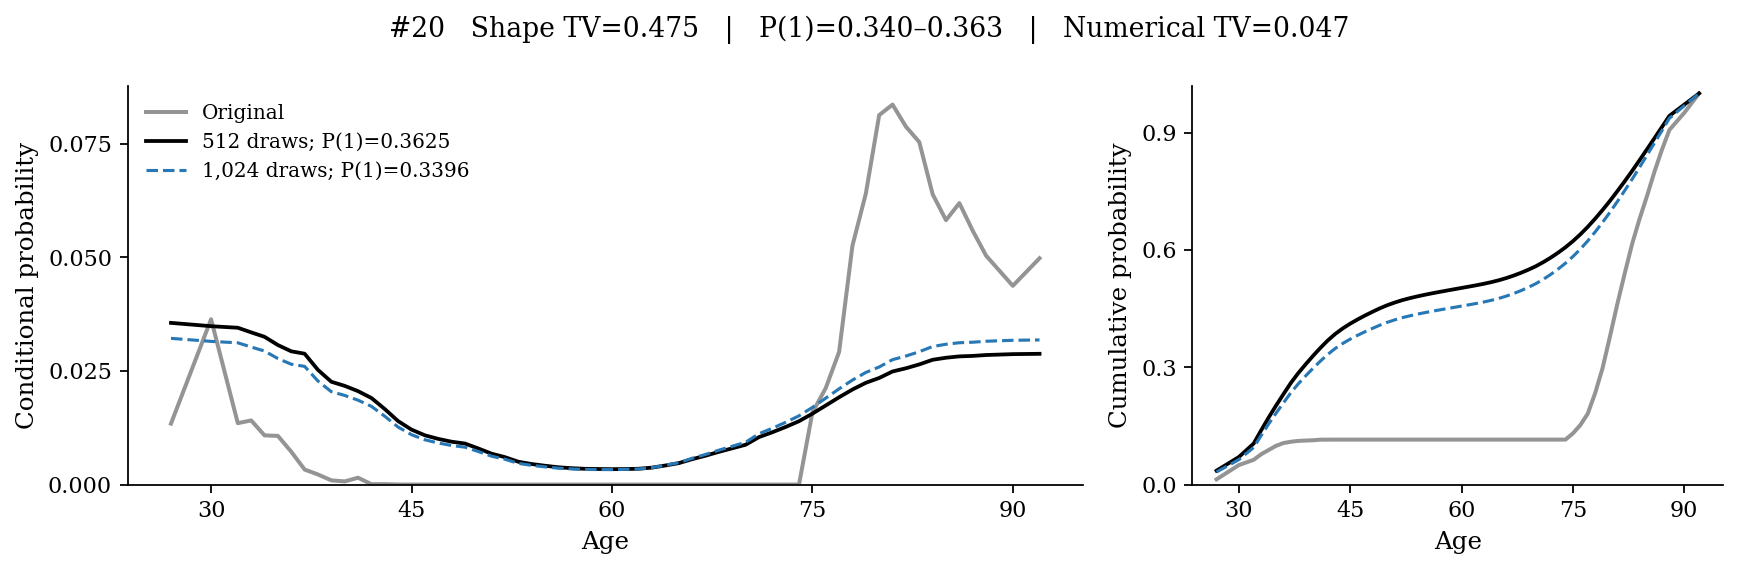

In [22]:
row=best.iloc[19]
display(Markdown(f"### #{row['rank']} — {row.stage}\n\n"
    f"**Auxiliary:** {row.auxiliary}  \n**Posterior:** {row.posterior}  \n"
    f"**Intercept:** {'Yes' if row.intercept else 'No'}; **Delta:** {row.Delta}; "
    f"**rho updates:** {row.rho_updates}; **rho initialization:** {row.initialization}.  \n"
    f"{row.preference_note}. Moment-equation residual: {row.moment_residual:.3g}."))
plot_candidate(row,curves,reference)


## Preference-restricted comparison and audit trail
Below: matched logistic/logistic fits only, excluding L1. Overall rank is retained,
so a restricted-subset leader cannot be mistaken for an overall top-20 result.
Intercept choice remains visible; no preference filters change the main ranking.


In [23]:
preferred=ranked[ranked.matched_logistic & ~ranked.contains_L1].head(10)
show_table(clear_tables(preferred)[0]);show_table(clear_tables(preferred)[1])
print('Exact sources for the overall top 20:')
display(best[['rank','primary_checkpoint','check_checkpoint']])


Rank,Auxiliary fit,Posterior fit,Intercept,Delta,Rho updates,Rho initialization,Matched logistic fits
27,Logistic FISTA 100 iterations; step multiplier=1 (no penalty),Logistic FISTA 100 iterations; step multiplier=1 (no penalty),Yes,1,1,identity,Yes
30,Logistic FISTA 1 iterations; step multiplier=1 (no penalty),Logistic FISTA 1 iterations; step multiplier=1 (no penalty),Yes,1,20,identity,Yes
31,Logistic GD 1 iterations; step multiplier=1 (no penalty),Logistic GD 1 iterations; step multiplier=1 (no penalty),Yes,1,20,identity,Yes
35,Logistic FISTA 1 iterations; step multiplier=1 (no penalty),Logistic FISTA 1 iterations; step multiplier=1 (no penalty),Yes,2,20,identity,Yes
36,Logistic GD 1 iterations; step multiplier=1 (no penalty),Logistic GD 1 iterations; step multiplier=1 (no penalty),Yes,2,20,identity,Yes
45,Logistic FISTA 1 iterations; step multiplier=1 (no penalty),Logistic FISTA 1 iterations; step multiplier=1 (no penalty),Yes,1,30,identity,Yes
46,Logistic GD 1 iterations; step multiplier=1 (no penalty),Logistic GD 1 iterations; step multiplier=1 (no penalty),Yes,1,30,identity,Yes
47,Logistic SAGA 1 epochs; seed=42 (no penalty),Logistic SAGA 1 epochs; seed=42 (no penalty),No,1,30,identity,Yes
50,Logistic SGD 1 epochs; step multiplier=1; seed=123 (no penalty),Logistic SGD 1 epochs; step multiplier=1; seed=123 (no penalty),No,1,30,identity,Yes
52,Logistic L2 4.21696503429e-05 (full solve),Logistic L2 4.21696503429e-05 (full solve),No,1,30,identity,Yes


Rank,"P(1), numerical range",Shape TV ↓,Check-to-check TV ↓,Conditional peak age,Min. mass above age 55,Rho moment residual,Study
27,0.9406 – 0.9422,0.597600,0.002900,84 – 85,1.000000,2.6,finite_intercept
30,0.5469 – 0.5523,0.612200,0.005200,71,0.730300,0.408,finite_intercept
31,0.5469 – 0.5523,0.612200,0.005200,71,0.730300,0.408,finite_intercept
35,0.5492 – 0.5544,0.622200,0.004900,71,0.743300,0.416,finite_intercept
36,0.5492 – 0.5544,0.622200,0.004900,71,0.743300,0.416,finite_intercept
45,0.5034 – 0.5053,0.640200,0.001400,71,0.584400,0.404,finite_intercept
46,0.5034 – 0.5053,0.640200,0.001400,71,0.584400,0.404,finite_intercept
47,0.5015 – 0.5070,0.642500,0.006800,69,0.583500,0.105,no_intercept_solver_sweep
50,0.5099 – 0.5233,0.646200,0.016500,68 – 69,0.600700,0.339,no_intercept_solver_sweep
52,0.5111 – 0.5209,0.648600,0.011900,66 – 68,0.596300,0.284,fully_solved_matched_L2


Exact sources for the overall top 20:


,rank,primary_checkpoint,check_checkpoint
0,1,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
1,2,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
2,3,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
3,4,results/myocardial_exploration_4026d0e775d2/de...,results/myocardial_exploration_4026d0e775d2/de...
4,5,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
5,6,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
6,7,results/myocardial_intercept_exploration_f53f5...,results/myocardial_intercept_exploration_f53f5...
7,8,results/myocardial_intercept_exploration_f53f5...,results/myocardial_intercept_exploration_f53f5...
8,9,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
9,10,results/myocardial_intercept_exploration_f53f5...,results/myocardial_intercept_exploration_f53f5...
